In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
def compute_metric(df,metric):
    dict_metric={}
    # Group by coref_chain to avoid repeated calculations
    group_by='coref_chain' if metric =='recall' else 'predicted_label'
    sum_over='predicted_label' if metric=='recall' else 'coref_chain'


    grouped = df.groupby(group_by)

    for coref_chain, df_temp in grouped:
        n = len(df_temp)
        total_links = n * (n - 1) / 2

        # Calculate predicted links using vectorized operations
        predicted_links = np.sum(df_temp[sum_over].value_counts().apply(lambda x: x * (x - 1) / 2))

        # Store recall value in the dictionary
        if total_links==0:
            #ignore predicted singletons
            dict_metric[coref_chain] =0
        else:
            dict_metric[coref_chain] = predicted_links / total_links

    df_temp = pd.DataFrame.from_dict(dict_metric,orient='index').reset_index()
    df_temp.columns=[group_by,metric]
    return df_temp
    

In [4]:
def dataset_start(filepath):

    predictions = pd.read_csv(filepath,delimiter=';',decimal=',')
    coref_chains = predictions[['coref_chain','pd_gold']].groupby(['coref_chain','pd_gold']).size().reset_index(name='num_mentions')
    predicted_clusters = predictions[['predicted_label','pd_predicted']].groupby(['predicted_label','pd_predicted']).size().reset_index(name='num_mentions')
    recall_df = compute_metric(predictions,'recall')
    precision_df = compute_metric(predictions,'precision')
    #Join dfs
    df_coref_chains_recall = coref_chains.merge(recall_df,on='coref_chain',how='left')
    df_coref_chains_recall = df_coref_chains_recall.sort_values(by=["pd_gold","coref_chain"],ascending=False).reset_index(drop=True)
    df_predicted_clusters_precision = predicted_clusters.merge(precision_df,on='predicted_label',how='left')
    df_predicted_clusters_precision = df_predicted_clusters_precision.sort_values(by=["pd_predicted","predicted_label"],ascending=False).reset_index(drop=True)

    return df_coref_chains_recall, df_predicted_clusters_precision

In [8]:
ecb_plus_entity_recall_best, ecb_plus_entity_precision_best = dataset_start(filepath="clusters_entity_ecbplus_test_best_model.csv")
ecb_plus_event_recall_best, ecb_plus_event_precision_best = dataset_start(filepath="clusters_event_ecbplus_test_best_model.csv")

newswcl50_entity_recall_best, newswcl50_entity_precision_best = dataset_start(filepath="clusters_entity_newswcl50_best_model.csv")
newswcl50_entity_recall_best_threshold, newswcl50_entity_precision_best_threshold = dataset_start(filepath="clusters_entity_newswcl50_best_model_threshold.csv")
newswcl50_event_recall_best, newswcl50_event_precision_best = dataset_start(filepath="clusters_event_newswcl50_best_model.csv")

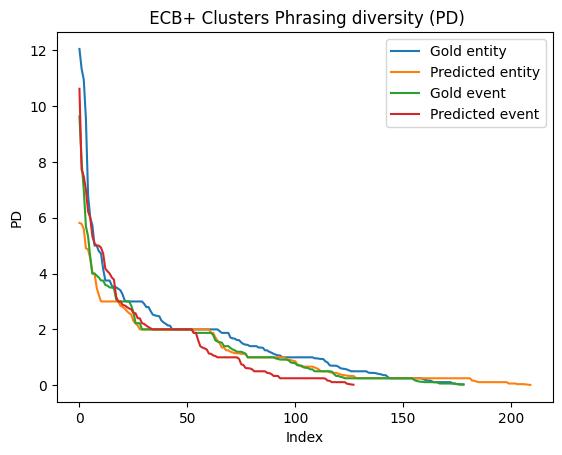

In [9]:
# Plotting both series on the same plot
plt.plot(ecb_plus_entity_recall_best['pd_gold'], label='Gold entity')
plt.plot(ecb_plus_entity_precision_best['pd_predicted'], label='Predicted entity')
plt.plot(ecb_plus_event_recall_best['pd_gold'], label='Gold event')
plt.plot(ecb_plus_event_precision_best['pd_predicted'], label='Predicted event')
# Adding labels and legend
plt.title(" ECB+ Clusters Phrasing diversity (PD)")
plt.xlabel('Index')
plt.ylabel('PD')
plt.legend()

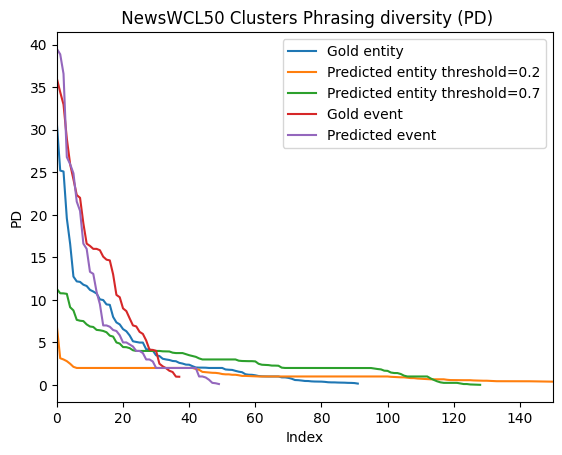

In [13]:
# Plotting both series on the same plot
plt.plot(newswcl50_entity_recall_best['pd_gold'], label='Gold entity')
plt.plot(newswcl50_entity_precision_best['pd_predicted'], label='Predicted entity threshold=0.2')
plt.plot(newswcl50_entity_precision_best_threshold['pd_predicted'], label='Predicted entity threshold=0.7')
plt.plot(newswcl50_event_recall_best['pd_gold'], label='Gold event')
plt.plot(newswcl50_event_precision_best['pd_predicted'], label='Predicted event')
# Adding labels and legend
plt.title(" NewsWCL50 Clusters Phrasing diversity (PD)")
plt.xlabel('Index')
plt.ylabel('PD')
# Trimming x-axis range to 150
plt.xlim(0, 150)
plt.legend()




